In [45]:
import numpy as np
import math
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
Nx = 200
cfl = 0.2 # CFL number
tmax = 1 # time from 0 to 1 (numerical one)
viscosity_coeff = (0.01/math.pi)

x = np.linspace(-1,1, 200)

# t = 0, I.C
u = -1 * np.sin(math.pi * x)
dx = abs(x[1] - x[0])

dt = cfl * dx / np.max(np.abs(u))
# dt = 0.002

nt = int(tmax/ dt) + 1

# nt = int(tmax/dt)

uf = np.zeros((nt,Nx))

uf[0, :] = u

print(nt)
print(dt)
print(nt*dt, tmax)

498
0.0020101128725153656
1.001036210512652 1


In [47]:
# u

In [48]:
# np.roll(u,-1)

In [49]:
def f(u):
    y = 0.5 * u ** 2
    yp = u
    return y, yp

In [50]:
def minmod(a,b):
    return 0.5 * (np.sign(a)+np.sign(b)) * np.minimum(np.abs(a), np.abs(b))

In [51]:
def RHS(u, dx, viscosity_coeff):
    # diffusion term
    diffusion_term = viscosity_coeff*(np.roll(u,1) - 2*u + np.roll(u,-1))/ dx**2
    
    ux = minmod((u-np.roll(u,1))/dx, (np.roll(u,-1) - u)/dx)
    
    uL = np.roll(u - 0.5 * dx * ux, 1)
    uR = u - 0.5 * dx * ux
    fL, fpL = f(uL)
    fR, fpR = f(uR)
    a = np.maximum(np.abs(fpL), np.abs(fpR))
    
    H = 0.5 * (fL + fR - a * (uR - uL)) # flux
    
    conv_term = - (np.roll(H,-1) - H)/dx
    y = conv_term + diffusion_term
    return y

In [52]:
# runge kutta
for i in range(1, nt):
    u1 = u + dt * RHS(u, dx, viscosity_coeff) # predictor
    u = 0.5 * u + 0.5 * (u1 + dt * RHS(u1, dx, viscosity_coeff))
    uf[i, :] = u

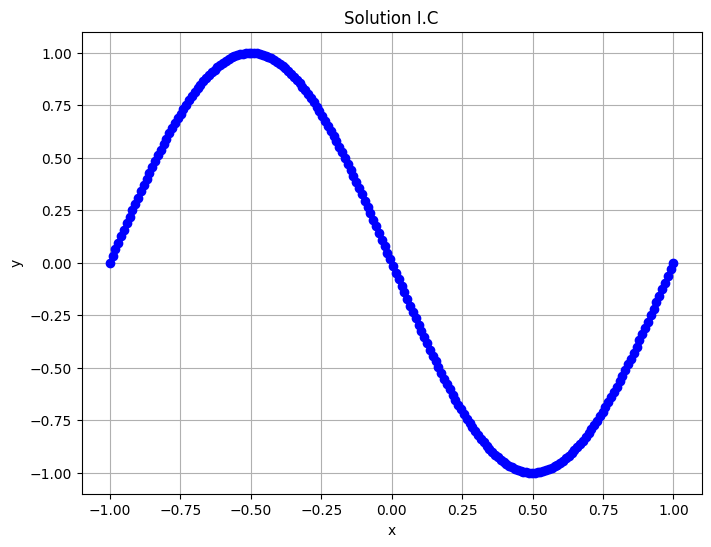

In [53]:
plt.figure(figsize=(8,6))
plt.plot(x, uf[0], '-o', color='b')
plt.title("Solution I.C")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

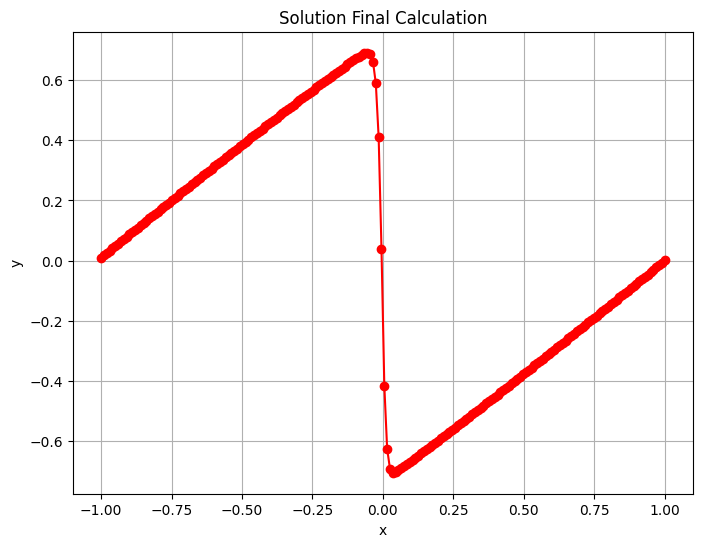

In [54]:
plt.figure(figsize=(8,6))
plt.plot(x, uf[-1], '-o', color='r')
plt.title("Solution Final Calculation")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

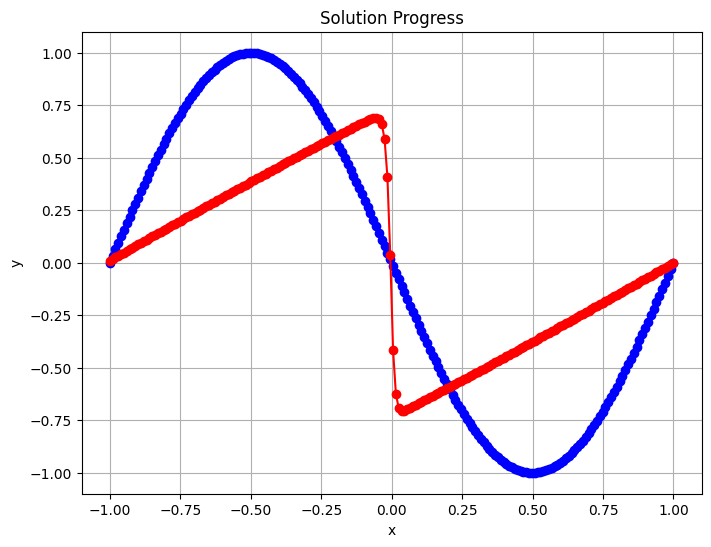

In [55]:
plt.figure(figsize=(8,6))
plt.plot(x, uf[0], '-o', color='b')
plt.plot(x, uf[-1], '-o', color='r')
plt.title("Solution Progress")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

In [56]:
sns.set_style("white")
plt.figure(figsize=(5,3), dpi= 3000)
sns.heatmap(uf.T, cmap="jet")

<Axes: >

In [57]:
from tqdm import tqdm
import torch
import torch.nn as nn

In [61]:
class NN(nn.Module):
    def __init__(self):
        super(NN, self).__init__()
        self.net = torch.nn.Sequential(
            nn.Linear(2,20),
            nn.Tanh(),
            nn.Linear(20,30),
            nn.Tanh(),
            nn.Linear(30,30),
            nn.Tanh(),
            nn.Linear(30,20),
            nn.Tanh(),
            nn.Linear(20,20),
            nn.Tanh(),
            nn.Linear(20,1)
        )

    def forward(self, x):
        out = self.net(x)
        return out

In [62]:
class Net:
    def __init__(self):
        device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
        
        self.model = NN().to(device)
        
        # comp. domain 
        self.h = 0.1
        self.k = 0.1
        x = torch.arange(-1,1+self.h, self.h)
        t = torch.arange(0,1+self.k, self.k)
        
        self.X = torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T
        
        # train data
        bc1 = torch.stack(torch.meshgrid(x[0],t)).reshape(2,-1).T
        bc2 = torch.stack(torch.meshgrid(x[-1],t)).reshape(2,-1).T
        ic  = torch.stack(torch.meshgrid(x,t[0])).reshape(2,-1).T
        self.X_train = torch.cat([bc1, bc2, ic])
        
        y_bc1 = torch.zeros(len(bc1))
        y_bc2 = torch.zeros(len(bc2))
        y_ic  = -torch.sin(math.pi * ic[:,0])
        print(y_ic)
        
        self.y_train = torch.cat([y_bc1, y_bc2, y_ic])
        self.y_train = self.y_train.unsqueeze(1)
        
        self.X = self.X.to(device)
        self.y_train = self.y_train.to(device)
        self.X_train = self.X_train.to(device)
        self.X.requires_grad = True
        
        # optimizer setting
        self.adam =  torch.optim.Adam(self.model.parameters())
        #Limited-memory Broyden-Fletcher-Goldfarb-Shanno (L-BFGS)
        self.optimizer = torch.optim.LBFGS(
            self.model.parameters(),
            lr=1.0,
            max_iter = 50000,
            max_eval = 50000,
            history_size = 50,
            tolerance_grad = 1e-7,
            tolerance_change = 1.0* np.finfo(float).eps,
            line_search_fn ="strong_wolfe"
        )
        
        self.criterion = torch.nn.MSELoss()
        self.iter = 1
    
    def loss_func(self):
        self.adam.zero_grad()
        self.optimizer.zero_grad()
        
        y_pred = self.model(self.X_train)
        loss_data = self.criterion(y_pred,self.y_train)
        
        u = self.model(self.X)
        
        du_dX = torch.autograd.grad(
            u,
            self.X,
            grad_outputs = torch.ones_like(u),
            create_graph = True,
            retain_graph = True
        )[0]
        
        #print(du_dX)
        #print("xxxxxxxxxxxxxxxxxxxxxxxxx")
        #print(du_dX[0])
        
        du_dt = du_dX[:,1]
        du_dx = du_dX[:,0]
        
        du_dXX = torch.autograd.grad(
            du_dX,
            self.X,
            grad_outputs = torch.ones_like(du_dX),
            create_graph = True,
            retain_graph = True
        )[0]
        
        du_dxx = du_dXX[:,0]
        
        loss_pde = self.criterion(du_dt + 1*u.squeeze()*du_dx , (0.01/math.pi) * du_dxx)
        
        loss = loss_pde + loss_data
        loss.backward()
        
        if self.iter % 100 == 0:
            print(self.iter, loss.item())
        self.iter = self.iter+1
        
        return loss
    
    def train(self):
        self.model.train()
        for i in range(1000):
            self.adam.step(self.loss_func)
        self.optimizer.step(self.loss_func)
    
    def eval_(self):
        self.model.eval()

In [63]:
# training
net = Net()
net.train()
net.model.eval()

tensor([-8.7423e-08,  3.0902e-01,  5.8779e-01,  8.0902e-01,  9.5106e-01,
         1.0000e+00,  9.5106e-01,  8.0902e-01,  5.8779e-01,  3.0902e-01,
         9.3627e-09, -3.0902e-01, -5.8779e-01, -8.0902e-01, -9.5106e-01,
        -1.0000e+00, -9.5106e-01, -8.0902e-01, -5.8779e-01, -3.0902e-01,
         8.7423e-08])


d:\PythonEnvs\tf_gpu\lib\site-packages\torch\autograd\graph.py:825: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


100 0.19339093565940857
200 0.09537726640701294
300 0.07582118362188339
400 0.05424260348081589
500 0.03300642594695091
600 0.019699253141880035
700 0.016136594116687775
800 0.01380486786365509
900 0.012423327192664146
1000 0.011389592662453651
1100 0.006496584974229336
1200 0.004269561730325222
1300 0.0022366391494870186
1400 0.001375798718072474
1500 0.0010667325695976615
1600 0.0008598314598202705
1700 0.0006721686804667115
1800 0.0005291657871566713
1900 0.00041156206862069666
2000 0.00033832096960395575
2100 0.0002901411789935082
2200 0.0002580623549874872
2300 0.00023174018133431673
2400 0.00020161780412308872
2500 0.0001787303772289306
2600 0.00016387026698794216
2700 0.0001493977615609765
2800 0.00013116431364323944
2900 0.00012017685367027298
3000 0.00010995751654263586
3100 0.00010196393122896552
3200 9.134910942520946e-05
3300 8.237473957706243e-05
3400 7.593318878207356e-05
3500 7.063486555125564e-05
3600 6.602840585401282e-05
3700 6.262646638788283e-05
3800 5.8527810324449

NN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=20, bias=True)
    (1): Tanh()
    (2): Linear(in_features=20, out_features=30, bias=True)
    (3): Tanh()
    (4): Linear(in_features=30, out_features=30, bias=True)
    (5): Tanh()
    (6): Linear(in_features=30, out_features=20, bias=True)
    (7): Tanh()
    (8): Linear(in_features=20, out_features=20, bias=True)
    (9): Tanh()
    (10): Linear(in_features=20, out_features=1, bias=True)
  )
)

In [64]:
h = 0.01
k = 0.01

x = torch.arange(-1,1,h)
t = torch.arange(0,1,k)

X= torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T
X= X.to(net.X.device)

model = net.model
model.eval()
with torch.no_grad():
    y_pred = model(X)
    y_pred = y_pred.reshape(len(x),len(t)).cpu().numpy()

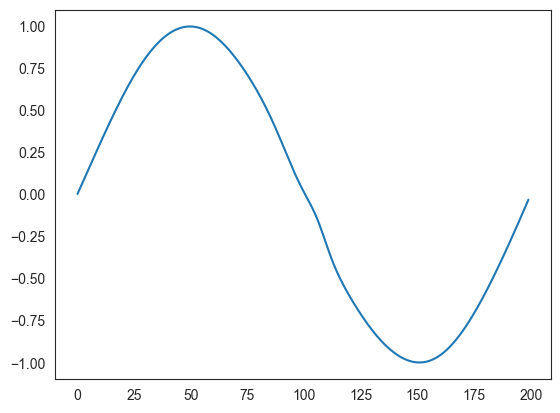

In [65]:
#I.C
plt.plot(y_pred[:,0])

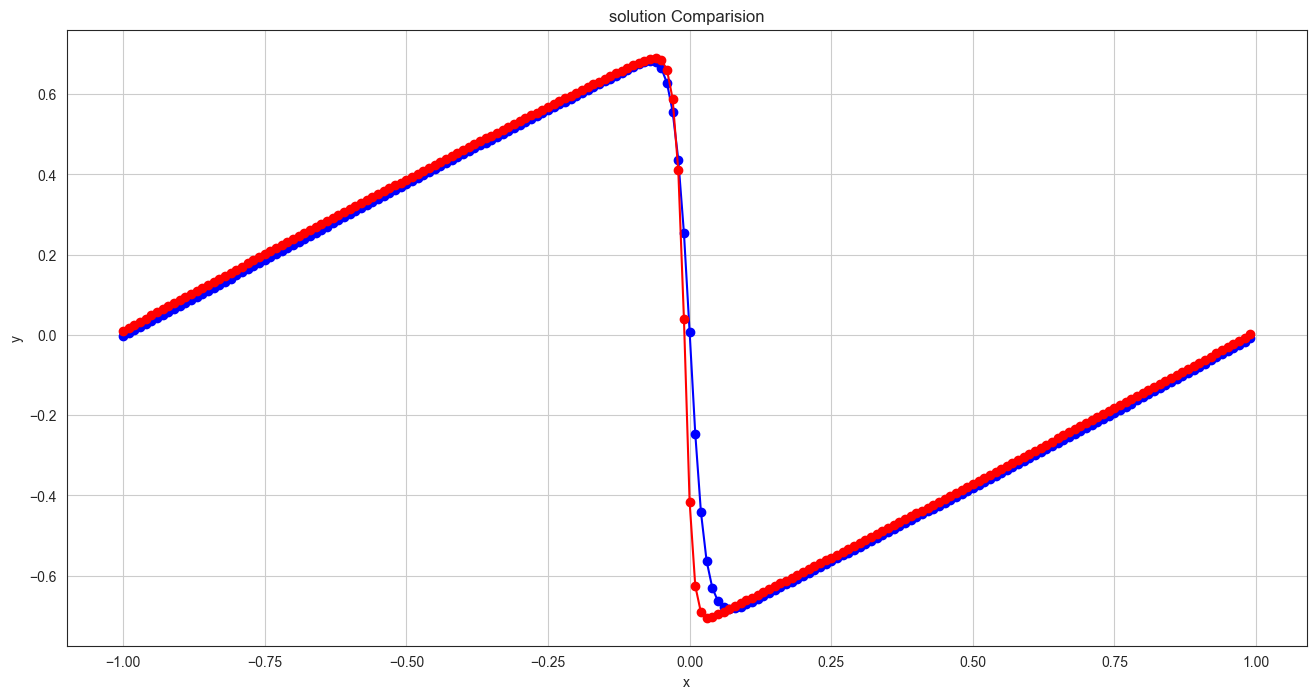

In [67]:
plt.figure(figsize=(16,8))
plt.plot(x, y_pred[:,-1], '-o', color = 'b') #PINNs
plt.plot(x, uf[-1], '-o', color = 'r') #TVD
plt.title("solution Comparision")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()